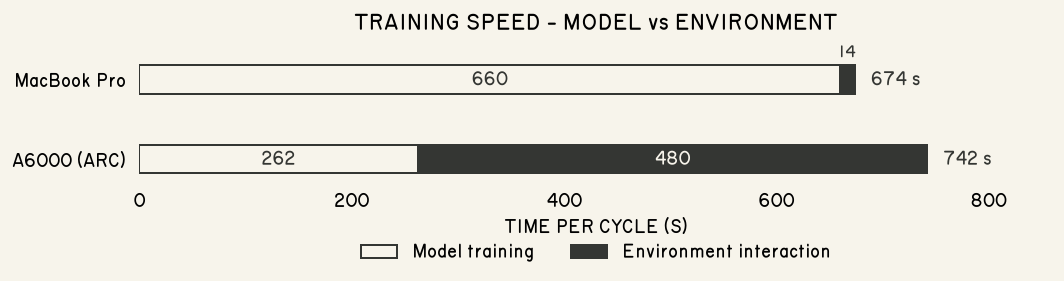

In [21]:
import matplotlib.pyplot as plt
import numpy as np

blk = "#343633"
off_white = "#F7F4EB"

plt.rcParams.update({
    "font.family": "Routed Gothic",
    "font.style": "normal",
    "font.size": 11,
    "figure.facecolor": off_white,
    "axes.facecolor": off_white,
    "figure.dpi": 120,
})

systems = ["MacBook Pro", "A6000 (ARC)"]
training = np.array([660, 262])
environment = np.array([14, 480])  # ARC: lower bound
totals = training + environment

fig, ax = plt.subplots(figsize=(9, 3.0))

y = np.array([1, 0])
h = 0.36

ax.barh(
    y,
    training,
    height=h,
    color=off_white,
    edgecolor=blk,
    linewidth=1.2,
    label="Model training",
)
ax.barh(
    y,
    environment,
    left=training,
    height=h,
    color=blk,
    edgecolor=blk,
    linewidth=1.2,
    label="Environment interaction",
)

# Segment labels
for i in range(2):
    ax.text(
        training[i] / 2, y[i], f"{training[i]}", ha="center", va="center", color=blk
    )

ax.text(
    training[1] + environment[1] / 2,
    y[1],
    "480",
    ha="center",
    va="center",
    color=off_white,
)

# Small MacBook environment segment
ax.text(667, y[0] + 0.24, "14", ha="center", va="bottom", color=blk, fontsize=10)

# Total time
ax.text(totals[0] + 15, y[0], "674 s", va="center", color=blk)
ax.text(totals[1] + 15, y[1], "742 s", va="center", color=blk)

ax.set_yticks(y, systems)
ax.set_xlim(0, 860)
ax.set_xticks(np.arange(0, 801, 200))
ax.set_xlabel("TIME PER CYCLE (S)")
ax.set_title("TRAINING SPEED - MODEL vs ENVIRONMENT", pad=18)

ax.spines[:].set_visible(False)
ax.tick_params(axis="both", length=0, pad=8)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=2)

plt.tight_layout()
plt.savefig("../../assets/slower-training.png", dpi=300, bbox_inches="tight")
plt.show()
